# Superstore Sales Performance & Profitability Analysis - Visualization
Notebook ini memvisualisasikan hasil 5 BQ dari tabel `mart_`

## 1. Import library

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from dotenv import load_dotenv
import os
from sqlalchemy import create_engine
from matplotlib.ticker import StrMethodFormatter

## 1.1 Load Environment & Database Connection

In [2]:
load_dotenv()

DB_HOST = os.getenv("DB_HOST")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

In [3]:
# Koneksi ke MySQL
engine = create_engine(f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

## 2. BQ1 - Segmen Pelanggan dengan Profit Tertinggi
Pertanyaan: Segmen pelanggan apa yang memberikan kontribusi profit paling tinggi?

In [4]:
query1 = """
    SELECT *
    FROM mart_customer_segment
"""
df_bq1 = pd.read_sql(query1, engine)

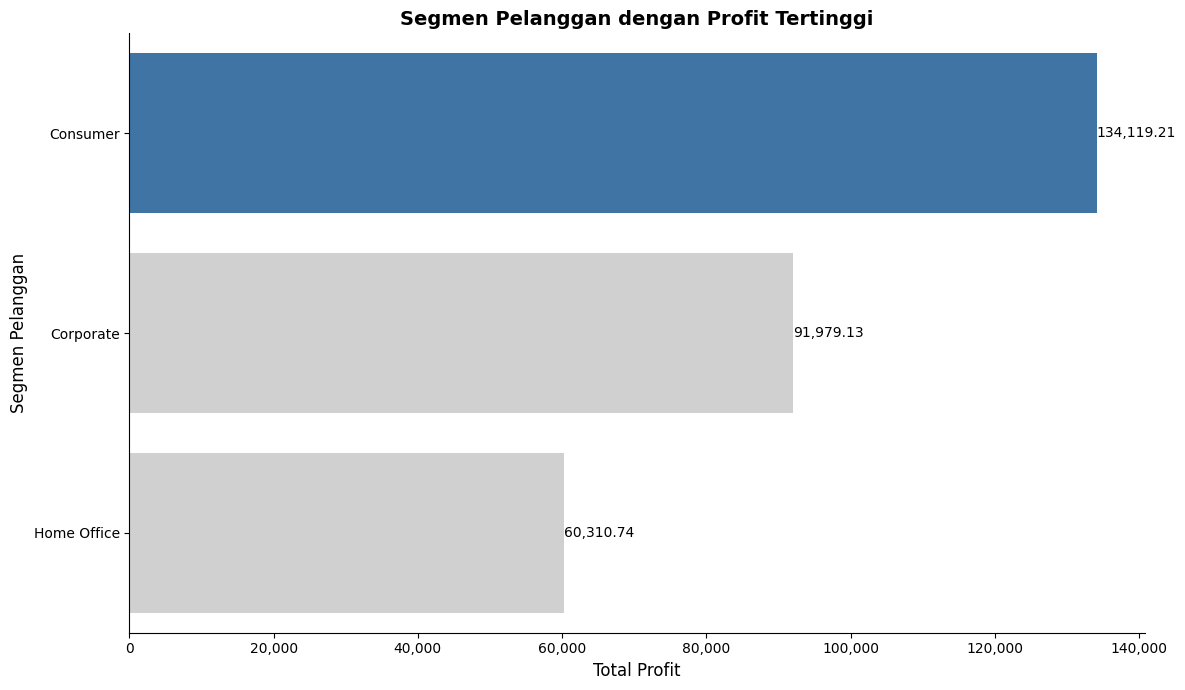

In [5]:
# Visualisasi BQ1
plt.figure(figsize=(12, 7))
color =('#2E75B6', '#D0D0D0', '#D0D0D0')
grafik_bq1 = sns.barplot(data=df_bq1, x='total_profit', y='segment', hue='segment', palette=color, legend=False)
plt.title('Segmen Pelanggan dengan Profit Tertinggi', fontweight='bold', fontsize=14)
for container in grafik_bq1.containers:
    plt.bar_label(container, fmt='{:,.2f}')
plt.xlabel('Total Profit', fontsize=12)
plt.ylabel('Segmen Pelanggan', fontsize=12)
plt.gca().xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

# Menghapus bingkai atas dan kanan
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

**Insight**: Berdasarkan data, segmen yang memberikan kontribusi profit paling tinggi adalah 'Consumer' dengan total profit sebesar 134,119.21. Namun, 'Home Office' memiliki profit margin tertinggi sebesar 14% dari total penjualannya, meskipun selisihnya tipis dibanding segmen lain (Corporate 13% dan Consumer 12%).

Catatan: Profit margin tidak ditampilkan di grafik.

## 3. BQ2 - Kategori dan Sub Kategori yang Mengalami Profit Minus Akibat Diskon

Pertanyaan: Kategori dan sub kategori apa saja yang paling banyak menghasilkan kerugian (profit minus) akibat strategi pemberian diskon?

In [6]:
query2 = """
    SELECT * 
    FROM mart_category_disc_loss
"""

df_bq2 = pd.read_sql(query2, engine)

In [7]:
# Membuat salinan DataFrame
df_bq2_copy = df_bq2.copy()

In [8]:
# Mengubah Angka 'discount' menjadi persentase
df_bq2_copy['discount'] = (df_bq2_copy['discount']*100).round(0).astype(int)

In [9]:
# Mengubah kolom 'discount' menjadi string
df_bq2_copy[['discount']] = df_bq2_copy[['discount']].astype(str)

# Mengabungkan kolom 'sub_category' dengan 'discount'
df_bq2_copy['info_lengkap'] = df_bq2_copy['sub_category'] + ' ' + '(' + df_bq2_copy['discount'] + '%' + ')'

In [10]:
# Membuat DataFrame untuk mengambil 5 baris teratas
df_bq2_top5 = df_bq2_copy.copy().head(5)

In [11]:
df_bq2_top5

,category,sub_category,discount,profit,profit_margin,info_lengkap
0,Office Supplies,Binders,80,-21909.40,-161.32,Binders (80%)
1,Technology,Machines,70,-19579.32,-125.50,Machines (70%)
2,Office Supplies,Binders,70,-16601.10,-73.59,Binders (70%)
3,Furniture,Tables,40,-16187.40,-35.49,Tables (40%)
4,Office Supplies,Appliances,80,-8629.64,-255.12,Appliances (80%)


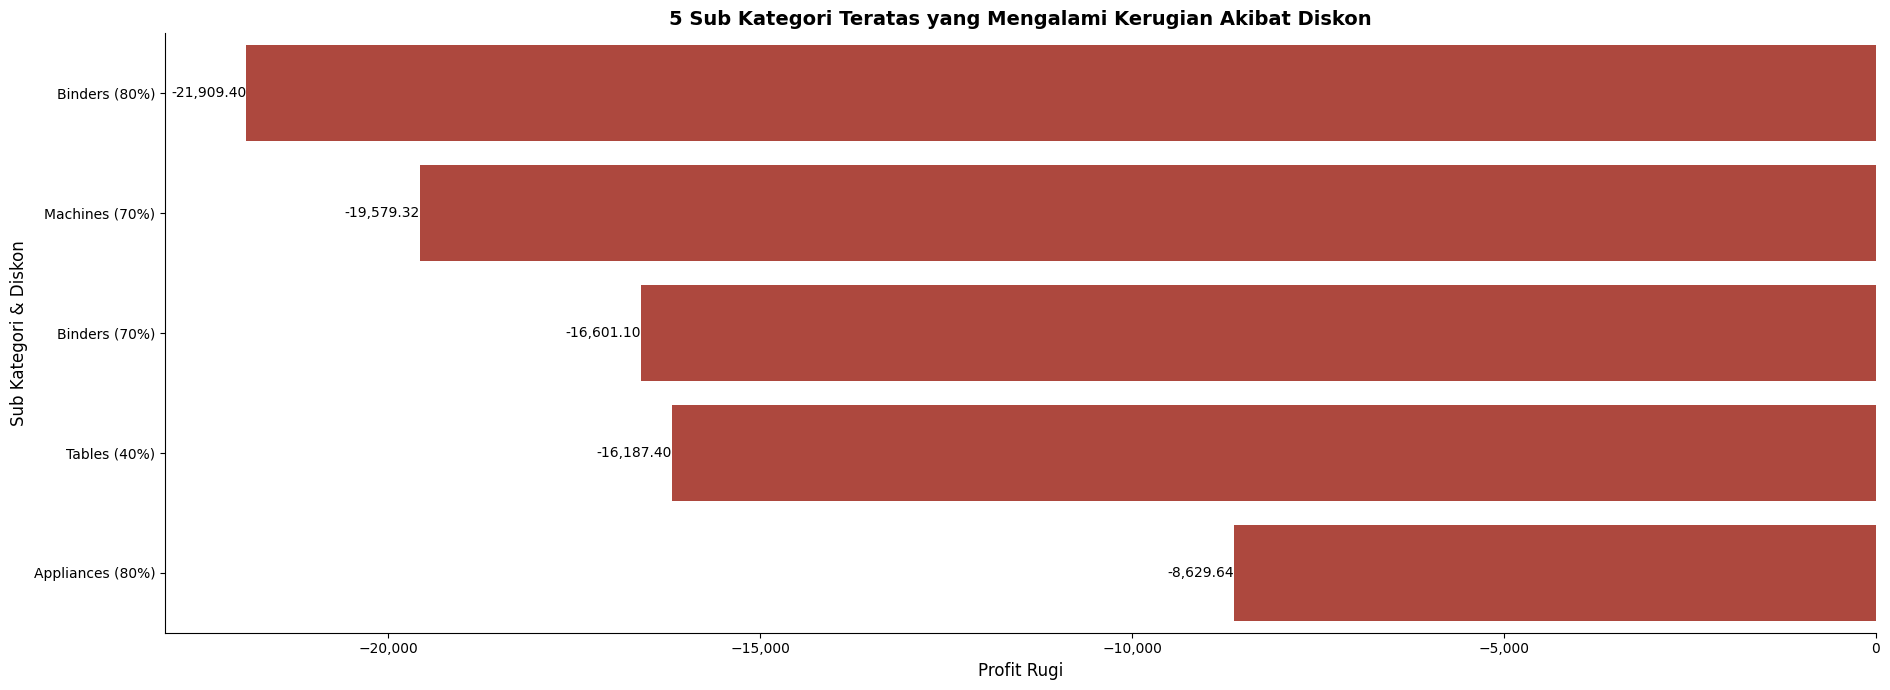

In [12]:
# Visualisasi BQ2
plt.figure(figsize=(19, 7))
grafik_bq2= sns.barplot(data=df_bq2_top5, x='profit', y='info_lengkap', color='#C0392B')
plt.title('5 Sub Kategori Teratas yang Mengalami Kerugian Akibat Diskon', fontweight='bold', fontsize=14)
plt.bar_label(grafik_bq2.containers[0], fmt='{:,.2f}')
plt.xlabel('Profit Rugi', fontsize=12)
plt.ylabel('Sub Kategori & Diskon', fontsize=12)
plt.gca().xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**Insight**: Berdasarkan data, kerugian nominal profit minus, terparahnya ada pada kategori 'Office Supplies' pada sub kategori 'Binders' dengan nilai kerugian sebesar -21,909.4 pada diskon yang diberikan sebesar 80%.

Kategori 'Office Supplies' pada sub kategori 'Appliances' menghasilkan kerugian nilai profit margin tertinggi sebesar -255% dari total penjualannya pada diskon 80% dengan nilai nominal profit yang dihasilkan sebesar -8,629.64. Sedangkan nilai profit margin kategori 'Office Supplies' pada sub kategori 'Binders' sebesar -161% (terparah kedua setelah 'Appliances').

Catatan: Profit margin tidak ditampilkan di grafik.

**Keterbatasan:** Angka kerugian yang dihasilkan hanya berlaku pada gabungan kategori, sub kategori, dan diskon tertentu. Secara keseluruhan kategori 'Office Supplies' memberikan total profit yang positif 122,490.8. Sehingga, analisis kerugian ini berpusat pada diskon tinggi bukan pada keseluruhan kategori.

## 4. BQ3 - Hubungan Penjualan dan Profit per Wilayah
Pertanyaan: Apakah wilayah geografis dengan jumlah penjualan tertinggi selalu berbanding lurus dengan profit yang tinggi?

In [13]:
query3 = """SELECT * 
    FROM mart_region_performance
"""

df_bq3 = pd.read_sql(query3, engine)

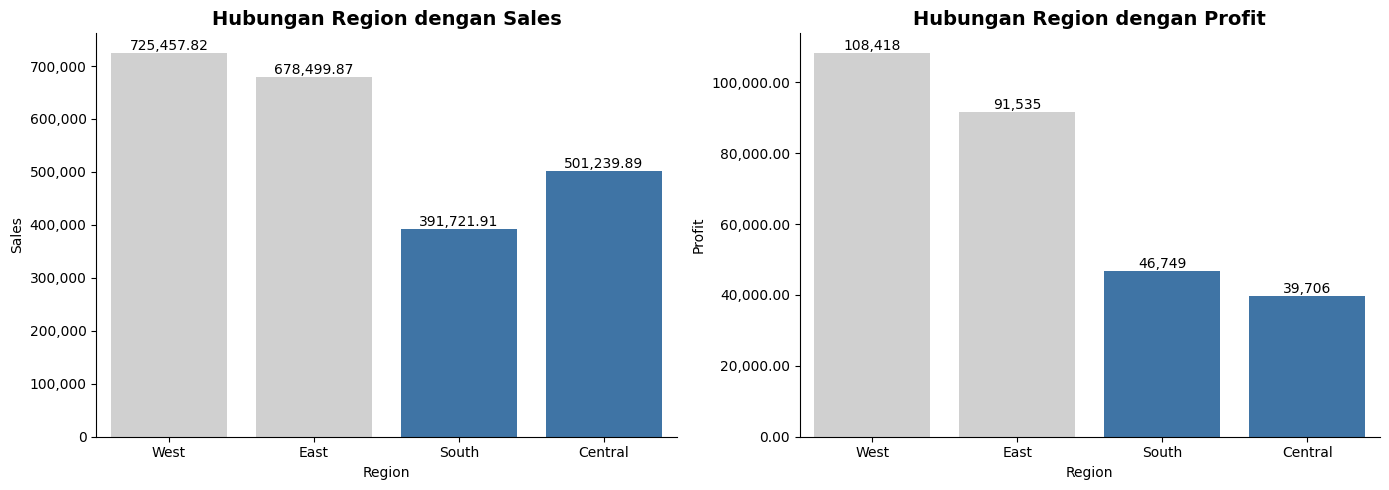

In [14]:
# Visualisasi BQ3
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
color =('#D0D0D0', '#D0D0D0', '#2E75B6','#2E75B6')

# Kotak 1 sebelah kiri - Untuk Sales
sns.barplot(data=df_bq3, x='region', y='sales', hue='region', palette=color, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='{:,.2f}')
axes[0].set_title('Hubungan Region dengan Sales', fontsize=14, fontweight='bold')
axes[0].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[0].set_xlabel('Region', fontsize=10)
axes[0].set_ylabel('Sales', fontsize=10)

# Kotak 2 sebelah kanan - Untuk Profit
sns.barplot(data=df_bq3, x='region', y='profit', hue='region', palette=color, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='{:,.0f}')
axes[1].set_title('Hubungan Region dengan Profit', fontsize=14, fontweight='bold')
axes[1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.2f}'))
axes[1].set_xlabel('Region', fontsize=10)
axes[1].set_ylabel('Profit', fontsize=10)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**Insight**: Berdasarkan data, wilayah yang memiliki sales tinggi tidak selalu memberikan profit yang tinggi juga. Dua wilayah tertinggi menghasilkan total sales dan total profit yang berbanding lurus, region 'West' menghasilkan total sales 725,457.82 dan total profit 108,418, diikuti oleh region 'East' dengan total sales 678,499.87 dan total profit 91,535.

Sedangkan dua wilayah di bawahnya menghasilkan profit yang tidak sejalan dengan total sales. Region 'South' menghasilkan profit 46,749 (total sales 391,721.91), lebih tinggi dari region 'Central' dengan profit 39,706 (total sales 501,239.89).

Catatan: Warna biru menandai region yang peringkatnya berbeda antara total sales dan total profit (Central dan South).

**Keterbatasan**: Analisis ini hanya memperlihatkan urutan total sales dan profit yang tidak sejalan tanpa menjelaskan penyebabnya.

## 5. BQ4 - Batas Diskon Maksimal yang Aman
Pertanyaan: Berapa batas persentase diskon maksimal (threshold) yang masih aman diberikan tanpa mengorbankan profitabilitas (kerugian)?

In [15]:
query4 = """SELECT *
    FROM mart_disc_threshold
"""

df_bq4 = pd.read_sql(query4, engine)

In [16]:
df_bq4['loss_row_count'] = (
    df_bq4['loss_row_count'].astype('int64')
)

In [17]:
# Membuat salinan DataFrame BQ4
df_bq4_copy = df_bq4.copy()

In [18]:
# Mengubah kolom 'discount' menjadi persentase
df_bq4_copy['discount'] = (df_bq4_copy['discount']*100).round(0).astype(int)

In [19]:
# Mengubah kolom 'discount' menjadi string
df_bq4_copy['discount'] = df_bq4_copy['discount'].astype(str)

# Menambahkan simbol % pada nilai discount
df_bq4_copy['discount'] = df_bq4_copy['discount'] + '%'

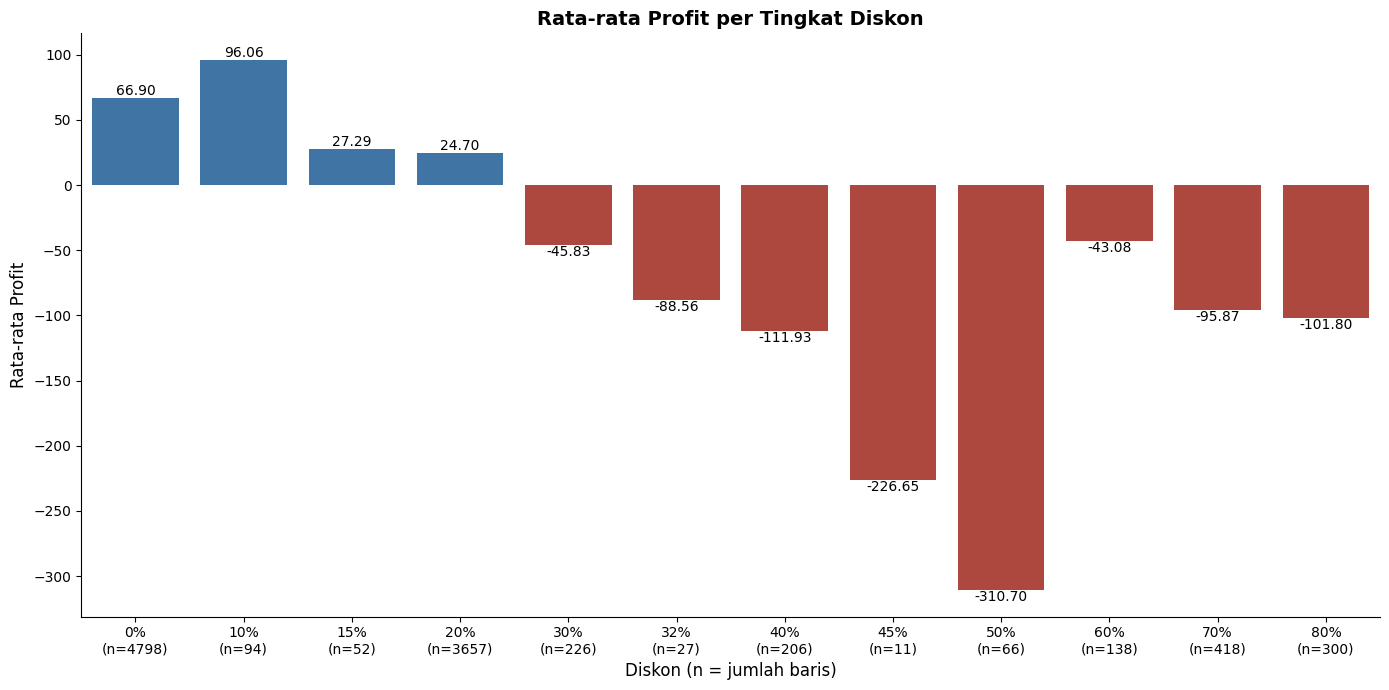

In [20]:
# Kolom label: diskon + jumlah baris (n)
df_bq4_copy['label'] = df_bq4_copy['discount'] + '\n(n=' + df_bq4_copy['total_rows'].astype(str) + ')'

# Warna: biru jika avg_profit positif, merah jika negatif
color = ['#2E75B6' if x > 0 else '#C0392B' for x in df_bq4_copy['avg_profit']]

# Visualisasi BQ4
plt.figure(figsize=(14, 7))
grafik_bq4 = sns.barplot(data=df_bq4_copy, x='label', y='avg_profit', hue='label', palette=color, legend=False)
for container in grafik_bq4.containers:
    plt.bar_label(container, fmt='{:,.2f}')
plt.title('Rata-rata Profit per Tingkat Diskon', fontweight='bold', fontsize=14)
plt.xlabel('Diskon (n = jumlah baris)', fontsize=12)
plt.ylabel('Rata-rata Profit', fontsize=12)
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**Insight**: Berdasarkan data, diskon 20% merupakan diskon tertinggi yang masih aman karena memenuhi tiga kriteria: rata-rata profit positif sebesar 24.7, total profit sebesar 90,337.31, dan persentase baris rugi yang jauh lebih rendah dibanding diskon di atasnya, yaitu 14% (502 dari 3,657 baris). Sebaliknya, diskon 30% memiliki rata-rata profit -45.83, total profit -10,357.22, dan persentase baris rugi yang tinggi sebesar 92% (207 dari 226 baris).

Catatan: 
- Total profit dan persentase baris rugi tidak ditampilkan di grafik.
- Warna biru menandai rata-rata profit positif dan merah menandai rata-rata profit negatif.

**Keterbatasan**: Tidak ada data diskon di antara 20% dan 30%, sehingga batas persisnya tidak dapat ditentukan. Batas aman sebenarnya berada di suatu titik antara 20% dan 30%.

## 6. BQ5 - Pengaruh Metode Pengiriman Terhadap Profitabilitas
Pertanyaan: Apakah metode pengiriman tertentu memiliki pengaruh terhadap tingkat profitabilitas?

In [21]:
query5 = """SELECT *
    FROM mart_ship_mode_profit
"""

df_bq5 = pd.read_sql(query5, engine)

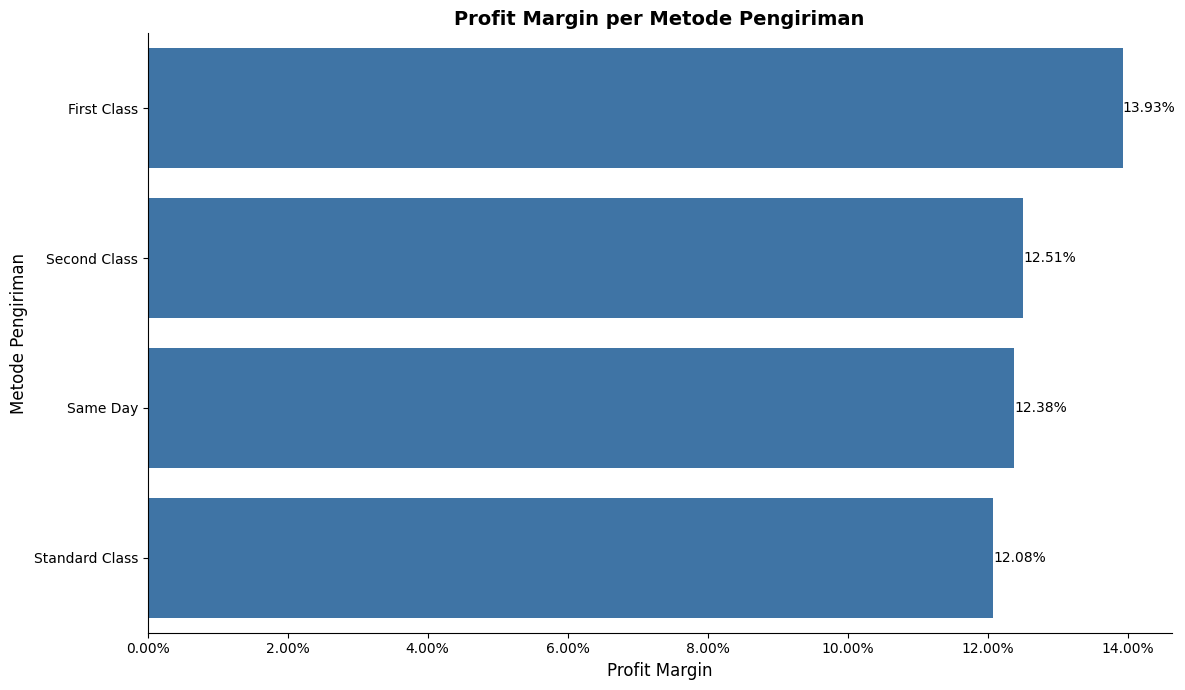

In [22]:
# Mengurutkan berdasarkan profit margin (dari besar ke kecil)
df_bq5_sorted = df_bq5.sort_values('profit_margin', ascending=False)

# Visualisasi BQ5
plt.figure(figsize=(12, 7))
grafik_bq5 = sns.barplot(data=df_bq5_sorted, x='profit_margin', y='ship_mode', color='#2E75B6')
plt.bar_label(grafik_bq5.containers[0], fmt='{:,.2f}%')
plt.title('Profit Margin per Metode Pengiriman', fontweight='bold', fontsize=14)
plt.xlabel('Profit Margin', fontsize=12)
plt.ylabel('Metode Pengiriman', fontsize=12)
plt.gca().xaxis.set_major_formatter(StrMethodFormatter('{x:,.2f}%'))

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**Insight**: Berdasarkan data, tidak ditemukan perbedaan berarti antar metode pengiriman karena pada profit margin dan rata-rata profit memiliki selisih yang tipis dengan rentang 12%-14% untuk profit margin dan 27.5-31.84 untuk rata-rata profit. 

Selain itu, pada total profit metode pengiriman 'Standard Class' memberikan kontribusi profit paling tinggi sebesar 164,100.85. Hal ini terjadi karena 'Standard Class' memiliki jumlah baris yang paling banyak, bukan karena lebih menguntungkan.

Catatan: Rata-rata profit dan total profit tidak ditampilkan di grafik.

**Keterbatasan**: Ini adalah analisis deskriptif tanpa adanya uji statistik, jadi hanya dapat menunjukkan bahwa selisihnya kecil, bukan berarti tidak ada pengaruh sama sekali.

## 7. Export Data untuk Dashboard

Mengeksport data mart yang asli dalam bentuk .csv ke dalam folder `../data/processed` untuk pembuatan dashboard di Tableau Public

In [23]:
df_bq1.to_csv('../data/processed/bq1_customer_segment.csv', index=False, sep=',')
df_bq2.to_csv('../data/processed/bq2_category_loss.csv', index=False, sep=',')
df_bq3.to_csv('../data/processed/bq3_region_performance.csv', index=False, sep=',')
df_bq4.to_csv('../data/processed/bq4_discount_threshold.csv', index=False, sep=',')
df_bq5.to_csv('../data/processed/bq5_ship_mode_profit.csv', index=False, sep=',')